## Imports

In [2]:
!python install_requirements.py;

In [2]:
import os
import random
from collections import Counter
import json

import pandas as pd
import numpy as np
from haversine import haversine, Unit

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.metrics import make_scorer, mean_squared_error

import xgboost as xgb
from xgboost import XGBRegressor

import torch

In [2]:
random.seed(1)
np.random.seed(1)
os.environ['PYTHONHASHSEED'] = str(1)

## Dataset

In [3]:
df = pd.read_csv("data/listings.csv")

In [4]:
df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)

In [5]:
price_median = df['price'].median()
df['price'] = df['price'].fillna(price_median)

In [6]:
df['host_is_superhost'] = df['host_is_superhost'].map({'t': 1, 'f': 0})

In [7]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=1) # this needs to be implemented

#### Spatial Features

In [8]:
city_center = (25.049589097552495, 121.5136645234154) # Taipei City Mall

In [9]:
def compute_distance(row): # add parameter for different 'centers'
    coords = (row['latitude'], row['longitude'])
    return haversine(city_center, coords, unit=Unit.KILOMETERS)

In [10]:
df['dist_to_cent'] = df.apply(compute_distance, axis=1)

#### Categorical Features

##### Neighbourhoods

In [11]:
nh_matrix = pd.get_dummies(df['neighbourhood_cleansed'])
nh_matrix = nh_matrix.add_prefix('nh_')
df = pd.concat([df, nh_matrix], axis=1)

In [12]:
nh_columns = [col for col in df.columns if col.startswith('nh_')]

##### Amenities

In [13]:
df['amenities'] = df['amenities'].apply(json.loads)

In [14]:
all_amenities = [amenity for sublist in df['amenities'] for amenity in sublist]
unique_amenities = sorted(set(all_amenities))

In [15]:
#count lock on bedroom door  

In [16]:
lower_threshold = 600 #600
upper_threshold = 5000 #5000
amenity_counts = Counter(all_amenities)

filtered_amenities = {
    amenity
    for amenity, count in amenity_counts.items()
    if lower_threshold <= count <= upper_threshold
}

In [17]:
def encode_amenities(row_amenities):
    return {
        amenity: int(amenity in row_amenities)
        for amenity in filtered_amenities # can be changed
    }

In [18]:
am_matrix = df['amenities'].apply(encode_amenities).apply(pd.Series)
am_matrix = am_matrix.add_prefix('am_')
df = pd.concat([df, am_matrix], axis=1)

In [19]:
am_columns = [col for col in df.columns if col.startswith('am_')]

##### Room types

In [20]:
rt_matrix = pd.get_dummies(df['room_type'])
rt_matrix = rt_matrix.add_prefix('rt_')
df = pd.concat([df, rt_matrix], axis=1)

In [21]:
rt_columns = [col for col in df.columns if col.startswith('rt_')]

#### Image Features

In [22]:
img = pd.read_csv("data/image_features.csv")

In [23]:
img = img.add_prefix('img_')
df = pd.concat([df, img], axis=1)

In [24]:
img_columns = [col for col in df.columns if col.startswith('img_')]

## Model

==== CONFIG ====

In [64]:
USE_LOG = True
CAP_HIGH = 15000
CAP_LOW = 300

FEATURE_GROUPS = {
    "base": ['accommodates', 'bathrooms', 'bedrooms', 'beds', 'review_scores_rating', 'dist_to_cent', 'minimum_nights', 'maximum_nights', 'host_is_superhost', 'host_total_listings_count', 'availability_eoy', 'host_listings_count', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'latitude', 'longitude'],
    "neighborhood": nh_columns,
    "amenities": am_columns,
    "room_type": rt_columns,
    "images": img_columns,
}

MODEL_NAME = "xgb"  # 'rf' or 'xgb'
TEST_SIZE = 0.2
RANDOM_SEED = 8

In [65]:
def get_model(name):
    if name == "rf":
        return RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED)
    elif name == "xgb":
        return XGBRegressor(subsample=0.8, n_estimators=500, learning_rate=0.05, max_depth=5, random_state=RANDOM_SEED, reg_alpha=3)

In [66]:
def preprocess_data(df, cap_low, cap_high, feature_groups, use_log):
    df = df.copy()
    df['price_capped'] = df['price'].clip(lower=cap_low, upper=cap_high)
    if use_log:
        df['target'] = np.log1p(df['price_capped'])
    else:
        df['target'] = df['price_capped']

    selected_features = []
    for group in feature_groups.values():
        selected_features += group

    X = df[selected_features].dropna()
    y = df.loc[X.index, 'target']

    #test
    #valid_idx = (df.loc[X.index, 'price'] < 8000) & (df.loc[X.index, 'price'] > 300)
    #X = X.loc[valid_idx]
    #y = y.loc[valid_idx]
    return X, y

In [67]:
def evaluate_model(model, X, y, use_log):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    if use_log:
        y_test_raw = np.expm1(y_test)
        y_pred_raw = np.expm1(y_pred)
    else:
        y_test_raw = y_test
        y_pred_raw = y_pred

    rmse = np.sqrt(mean_squared_error(y_test_raw, y_pred_raw))
    mape = np.mean(np.abs((y_test_raw - y_pred_raw) / y_test_raw)) * 100

    print(f"RMSE: {rmse:.2f}")
    print(f"MAPE: {mape:.2f}%")

    return y_test_raw, y_pred_raw

In [68]:
def plot_results(y_true, y_pred, label=''):
    residuals = y_true - y_pred

    plt.figure(figsize=(8, 6))
    plt.scatter(y_true, y_pred, alpha=0.5, edgecolor='k')
    plt.plot([0, y_true.max()], [0, y_true.max()], color='red', lw=2, label='Perfect prediction')
    plt.xlabel('True Price')
    plt.ylabel('Predicted Price')
    plt.title(f'Predicted vs True Prices {label}')
    plt.grid(True)
    plt.legend()
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.scatter(y_true, residuals, alpha=0.5, edgecolor='k')
    plt.axhline(0, color='red')
    plt.xlabel('True Price')
    plt.ylabel('Residuals')
    plt.title(f'Residuals vs True Price {label}')
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.scatter(y_pred, residuals, alpha=0.5, edgecolor='k')
    plt.axhline(0, color='red')
    plt.xlabel('Predicted Price')
    plt.ylabel('Residuals')
    plt.title(f'Residuals vs Predicted Price {label}')
    plt.grid(True)
    plt.show()

In [69]:
X, y = preprocess_data(df, CAP_LOW, CAP_HIGH, FEATURE_GROUPS, USE_LOG)

In [70]:
model = get_model(MODEL_NAME)
y_true, y_pred = evaluate_model(model, X, y, use_log=USE_LOG)

RMSE: 1157.75
MAPE: 26.36%


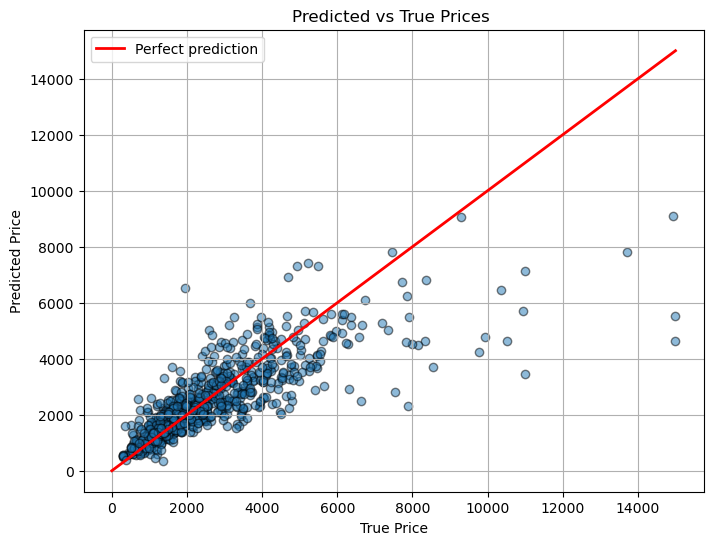

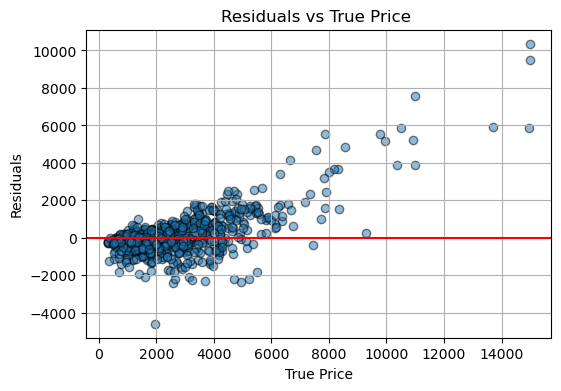

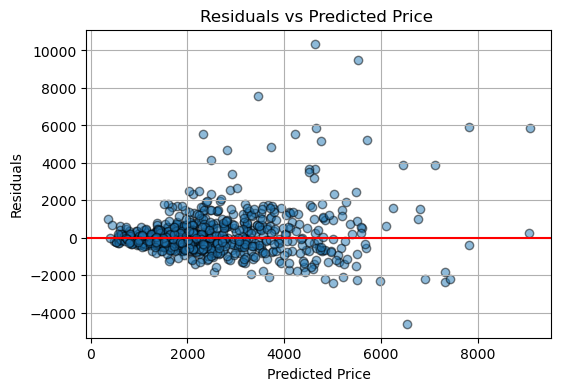

In [71]:
plot_results(y_true, y_pred)

Todo:
- Outliers?
- Capping features (eg: bedrooms/bathrooms in hostels)
- Split data properly
- Implement k-fold cross-validation
- Use GridSearchCV or RandomizedSearchCV for systematic hyperparameter optimization
- Add features: sentiment analysis on reviews, CNN-based image embeddings, text embeddings for titles/descriptions
- Tweak amenities (normalization, categories)
- Correlation analysis after adding all features
- PCA for dimensionality reduction
- Pipeline?


Sentiment Analysis Models:
- English, German, French, "Somali" -> nlptown/bert-base-multilingual-uncased-sentiment (Normalize Stars to 0.0 - 1.0)
- Chinese/Taiwanese -> SnowNLP
- Korean -> WhitePeak/bert-base-cased-Korean-sentiment (Output?)

In [42]:
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.8, 1.0],
}

# First split data once for tuning and evaluation
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED)

# Do RandomizedSearchCV on training+validation data
random_search = RandomizedSearchCV(
    XGBRegressor(),
    param_distributions=param_dist,
    n_iter=20,
    scoring='neg_mean_absolute_percentage_error',
    cv=5,
    verbose=1,
    random_state=42
)

random_search.fit(X_train_val, y_train_val)

print("Best hyperparameters:", random_search.best_params_)

# Now evaluate the best model on the held-out test set
best_model = random_search.best_estimator_

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best hyperparameters: {'subsample': 1.0, 'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.05}


In [43]:
def evaluate_model2(model, X_test, y_test, use_log):
    y_pred = model.predict(X_test)

    if use_log:
        y_test_raw = np.expm1(y_test)
        y_pred_raw = np.expm1(y_pred)
    else:
        y_test_raw = y_test
        y_pred_raw = y_pred

    rmse = np.sqrt(mean_squared_error(y_test_raw, y_pred_raw))
    mape = np.mean(np.abs((y_test_raw - y_pred_raw) / y_test_raw)) * 100

    print(f"RMSE: {rmse:.2f}")
    print(f"MAPE: {mape:.2f}%")

    return y_test_raw, y_pred_raw

y_true, y_pred = evaluate_model2(best_model, X_test, y_test, use_log=USE_LOG)

RMSE: 1227.32
MAPE: 25.97%


/opt/conda/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21335 (\N{CJK UNIFIED IDEOGRAPH-5357}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 28207 (\N{CJK UNIFIED IDEOGRAPH-6E2F}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21312 (\N{CJK UNIFIED IDEOGRAPH-5340}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21516 (\N{CJK UNIFIED IDEOGRAPH-540C}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/

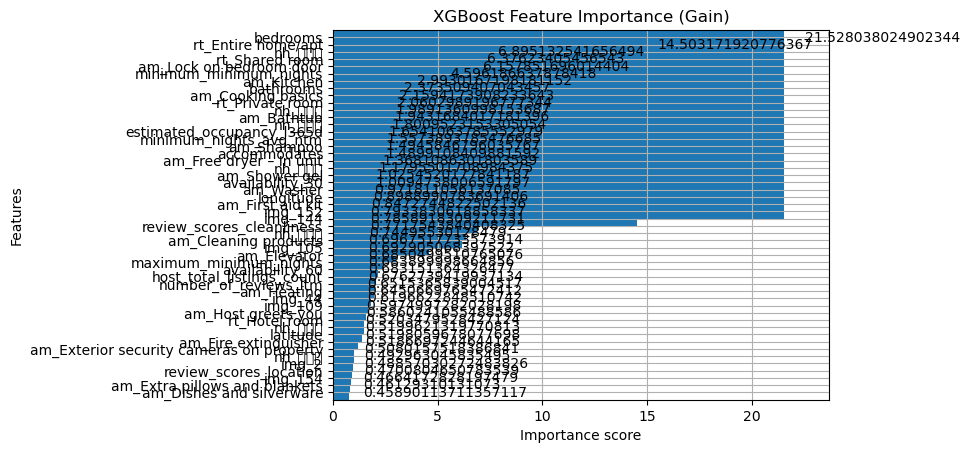

In [55]:
xgb.plot_importance(best_model, importance_type='gain', max_num_features=50, height=50)
plt.title('XGBoost Feature Importance (Gain)')
plt.show()

#### Correlations

In [114]:
def feature_correlations(feature_group):
    corr = df.copy()
    corr['price_capped'] = corr['price'].clip(300, 15000)

    selected_features = FEATURE_GROUPS[feature_group]

    correlations = corr[selected_features + ['price_capped']].corr()['price_capped']

    print(correlations.sort_values(ascending=False))

In [115]:
feature_correlations("base")

price_capped                   1.000000
bedrooms                       0.495128
accommodates                   0.486934
beds                           0.406965
bathrooms                      0.257313
latitude                       0.086871
review_scores_cleanliness      0.085937
review_scores_rating           0.072585
availability_30                0.068305
review_scores_accuracy         0.068012
longitude                      0.060237
availability_60                0.059696
review_scores_checkin          0.057867
host_is_superhost              0.046587
dist_to_cent                   0.044541
availability_90                0.042497
review_scores_communication    0.032335
maximum_nights                 0.030784
availability_eoy               0.025571
availability_365               0.017954
review_scores_location         0.016894
maximum_maximum_nights         0.009420
minimum_maximum_nights         0.006018
maximum_nights_avg_ntm         0.004055
review_scores_value            0.000599


In [116]:
feature_correlations("neighborhood")

price_capped    1.000000
nh_內湖區          0.083768
nh_大同區          0.065649
nh_北投區          0.046657
nh_松山區          0.029745
nh_文山區          0.018482
nh_大安區          0.018016
nh_中山區          0.011637
nh_信義區         -0.004526
nh_中正區         -0.012045
nh_士林區         -0.013112
nh_南港區         -0.019381
nh_萬華區         -0.088348
Name: price_capped, dtype: float64


In [62]:
feature_correlations("amenities")

price_capped                   1.000000
am_Pack ’n play/Travel crib    0.207269
am_High chair                  0.179740
am_Bathtub                     0.175222
am_Dining table                0.157377
                                 ...   
am_Lockbox                    -0.062983
am_Shared patio or balcony    -0.072424
am_Mini fridge                -0.078964
am_Private living room        -0.111279
am_Lock on bedroom door       -0.240577
Name: price_capped, Length: 233, dtype: float64


In [61]:
feature_correlations("room_type")

price_capped          1.000000
rt_Entire home/apt    0.247517
rt_Hotel room         0.035718
rt_Shared room       -0.105663
rt_Private room      -0.234632
Name: price_capped, dtype: float64


In [63]:
feature_correlations("images")

price_capped    1.000000
img_2           0.153465
img_4           0.126114
img_21          0.079484
img_14          0.061387
                  ...   
img_131        -0.045613
img_95         -0.056497
img_7          -0.061974
img_5          -0.073110
img_1          -0.132178
Name: price_capped, Length: 275, dtype: float64


#### Hyperparameter Optimization

#### Testing:

In [119]:
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.8, 1.0],
}

xgb = XGBRegressor()
random_search = RandomizedSearchCV(
    xgb,
    param_distributions=param_dist,
    n_iter=20,  
    scoring='neg_mean_absolute_percentage_error',
    cv=5,
    verbose=1,
    random_state=42
)

In [ ]:
y_true, y_pred = evaluate_model(random_search, X, y, use_log=USE_LOG)
print("Best hyperparameters:", random_search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


In [122]:
residuals = y_true - y_pred
re = residuals / y_true
results_df = pd.DataFrame({
    'true_price': round(y_true, 2),
    'predicted_price': y_pred.round(decimals=2),
    'residuals' : round(residuals, 2),
    'relative error' : round(re * 100, 2)
})

In [123]:
results_df.to_csv('data/xgboost_results.csv', index=False)

In [34]:
pd.set_option('display.max_rows', None)  # Show all rows

In [35]:
corr = df.copy()
corr['price_capped'] = corr['price'].clip(lower=300, upper=15000)
selected_features = []
selected_features += FEATURE_GROUPS["images"]
print(corr[selected_features + ['price_capped']].corr()['price_capped'].sort_values(ascending=False))

price_capped    1.000000
img_14          0.175553
img_389         0.133808
img_170         0.131993
img_26          0.131925
img_335         0.131492
img_2           0.129783
img_39          0.127390
img_479         0.126691
img_160         0.124770
img_311         0.122293
img_67          0.121200
img_290         0.120026
img_1           0.118774
img_17          0.116191
img_433         0.112049
img_18          0.111613
img_462         0.108311
img_258         0.107082
img_173         0.106226
img_189         0.103767
img_503         0.101691
img_252         0.101200
img_465         0.098521
img_73          0.097515
img_407         0.092481
img_440         0.092422
img_456         0.088253
img_330         0.087007
img_331         0.086720
img_490         0.086373
img_305         0.086038
img_435         0.085699
img_72          0.085571
img_317         0.084104
img_495         0.084092
img_159         0.083917
img_410         0.083405
img_340         0.083259
img_371         0.082791


In [50]:
corr_all = df.copy()
corr_all['price_capped'] = corr_all['price'].clip(lower=300, upper=15000)
selected_features = []
for group in FEATURE_GROUPS.values():
        selected_features += group
print(corr_all[selected_features + ['price_capped']].corr()['price_capped'].sort_values(ascending=False))

price_capped                                                                              1.000000
bedrooms                                                                                  0.495128
accommodates                                                                              0.486934
beds                                                                                      0.406965
bathrooms                                                                                 0.257313
rt_Entire home/apt                                                                        0.247517
am_Pack ’n play/Travel crib                                                               0.207269
am_High chair                                                                             0.179740
am_Bathtub                                                                                0.175222
am_Dining table                                                                           0.157377
am_Childre

In [117]:
def evaluate_model_kfold(model, X, y, use_log, k):
    kf = KFold(n_splits=k, shuffle=True, random_state=69)

    all_y_true = []
    all_y_pred = []
    
    for train_index, test_index in kf.split(X):
        X, y = preprocess_data(df, CAP_LOW, CAP_HIGH, FEATURE_GROUPS, USE_LOG)
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        if use_log:
            y_test_raw = np.expm1(y_test)
            y_pred_raw = np.expm1(y_pred)
        else:
            y_test_raw = y_test
            y_pred_raw = y_pred

        rmse = np.sqrt(mean_squared_error(y_test_raw, y_pred_raw))
        mape = np.mean(np.abs((y_test_raw - y_pred_raw) / y_test_raw)) * 100

        print(f"RMSE: {rmse:.2f}")
        print(f"MAPE: {mape:.2f}%")

        all_y_true.extend(y_test_raw)
        all_y_pred.extend(y_pred_raw)

    all_y_true = np.array(all_y_true)
    all_y_pred = np.array(all_y_pred)

    rmse = np.sqrt(mean_squared_error(all_y_true, all_y_pred))
    mape = np.mean(np.abs((all_y_true - all_y_pred) / all_y_true)) * 100

    print(f"Average RMSE: {rmse:.2f}")
    print(f"Average MAPE: {mape:.2f}%")

    return all_y_true, all_y_pred

In [118]:
model = get_model(MODEL_NAME)
y_true, y_pred = evaluate_model_kfold(model, X, y, use_log=USE_LOG,k=10)

RMSE: 975.41
MAPE: 23.71%
RMSE: 898.54
MAPE: 25.18%
RMSE: 859.00
MAPE: 20.92%
RMSE: 970.93
MAPE: 23.75%
RMSE: 755.96
MAPE: 24.36%
RMSE: 845.79
MAPE: 24.31%
RMSE: 780.11
MAPE: 22.90%
RMSE: 816.20
MAPE: 25.67%
RMSE: 845.58
MAPE: 21.57%
RMSE: 808.72
MAPE: 24.57%
Average RMSE: 858.49
Average MAPE: 23.69%


In [58]:
def evaluate_best_model(X, y, use_log, param_dist):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED)

    search = RandomizedSearchCV(
        XGBRegressor(),
        param_distributions=param_dist,
        n_iter=20,
        scoring='neg_mean_absolute_percentage_error',
        cv=5,
        random_state=42,
        verbose=1
    )
    search.fit(X_train, y_train)
    print("Best hyperparameters:", search.best_params_)

    best_model = XGBRegressor(**search.best_params_)
    best_model.fit(X_train, y_train)
    y_pred = best_model.predict(X_test)

    if use_log:
        y_test_raw = np.expm1(y_test)
        y_pred_raw = np.expm1(y_pred)
    else:
        y_test_raw = y_test
        y_pred_raw = y_pred

    rmse = np.sqrt(mean_squared_error(y_test_raw, y_pred_raw))
    mape = np.mean(np.abs((y_test_raw - y_pred_raw) / y_test_raw)) * 100

    print(f"RMSE: {rmse:.2f}")
    print(f"MAPE: {mape:.2f}%")

    return y_test_raw, y_pred_raw

In [38]:
y_true, y_pred = evaluate_best_model(X, y, use_log=USE_LOG, param_dist=param_dist)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best hyperparameters: {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 10, 'learning_rate': 0.05}
RMSE: 997.50
MAPE: 22.74%


- Evaluate model with buckets
- Test image features with uncapped prices